### 02 — Feature selection, embedding and batch integration

---

 Eight samples- one protocol and one scRNAseq chemistry. My batch effects are small.
Meanwhile the thing I am trying to measure — the transcriptional
consequence of deleting Bola3 — is a *sample-level* difference

Batch correction algorithms cannot tell the difference between "this sample
differs for technical reasons" and "this sample differs because the mouse had
no Bola3". Both look like the same thing: a shift between samples. So:

> **Set `batch_key` to `sample_id`, never to `genotype`.** And be aware that
> even correcting on `sample_id` removes part of your genotype signal, because
> genotype is nested inside sample.

This is why the **differential expression in notebook 05 is done on raw counts
with a pseudobulk model, not on the integrated embedding.** The integration
here exists to give you a clean UMAP and clean cell-type labels. It is a
visualisation and annotation tool. It is not where your statistics come from.

The notebook therefore starts by asking whether I need to do integration at all.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import config as cfg
from integration import batch_mixing_score, harmony_integrate
from snapseed_lite import load_hierarchy

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False, figsize=(4.5, 4.5))
sc.settings.figdir = cfg.FIG_DIR
np.random.seed(cfg.RANDOM_SEED)

adata = sc.read_h5ad(cfg.H5AD["qc"])
print(adata)

AnnData object with n_obs × n_vars = 78760 × 22679
    obs: 'genotype', 'mouse_id', 'sex', 'batch', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'total_counts_hormone', 'pct_counts_hormone', 'z_outlier', 'below_valley', 'doublet_score', 'predicted_doublet', 'qc_fail', 'qc_reason'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'hormone', 'n_cells'
    uns: 'log1p'
    layers: 'counts', 'lognorm'


### 2.1 Highly variable genes

 `seurat_v3` is the right flavour because it operates on raw
counts and models the mean–variance relationship explicitly; the batch key
makes it pick genes that are variable *within* samples rather than genes that
merely differ *between* samples.

### Why hormone genes are excluded here

Islet scRNA-seq has a problem no brain-organoid atlas has: a handful of genes
account for an enormous share of every library. `Ins1` and `Ins2` can be 30–50%
of counts in a beta cell, and their ambient background contaminates every other
barcode. CellBender removes most of that, but residual insulin is still the
single most "variable" feature in the dataset — and it is variable for
technical reasons.

Left in, hormone genes dominate the PCs and you get a UMAP organised by ambient
load. They are excluded from **feature selection only**. They remain in the
object, are used for annotation, and are fully tested in the DE in notebook 05.

In [2]:
hierarchy, flat_markers, ambient_prone = load_hierarchy(cfg.MARKER_YAML)

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=cfg.N_HVG,
    flavor=cfg.HVG_FLAVOR,
    batch_key="sample_id",
    layer="counts",
    subset=False,
)

excluded = adata.var_names.isin(ambient_prone) & adata.var["highly_variable"]
print(f"{excluded.sum()} ambient-prone hormone/enzyme genes removed from the HVG set:")
print("  " + ", ".join(adata.var_names[excluded]))
adata.var["highly_variable"] = adata.var["highly_variable"] & ~adata.var_names.isin(ambient_prone)

# sex chromosome genes drive a split that has nothing to do with genotype
sex_genes = [g for g in ["Xist", "Tsix", "Ddx3y", "Eif2s3y", "Uty", "Kdm5d"]
             if g in adata.var_names]
if adata.obs["sex"].nunique() > 1 and sex_genes:
    adata.var["highly_variable"] &= ~adata.var_names.isin(sex_genes)
    print(f"mixed-sex cohort: also removed {sex_genes} from HVGs")

print(f"\nfinal HVG set: {adata.var['highly_variable'].sum()} genes")
print(f"Bola3 in HVGs: {bool(adata.var.loc['Bola3', 'highly_variable']) if 'Bola3' in adata.var_names else 'n/a'}")

16 ambient-prone hormone/enzyme genes removed from the HVG set:
  Cel, Gcg, Cpa1, Try5, Reg3b, Reg2, Reg1, Ghrl, Ctrb1, Ppy, Pyy, Cela1, Sst, Clps, Ttr, Pnlip

final HVG set: 1984 genes
Bola3 in HVGs: False


### 2.2 Unintegrated embedding — the baseline you must look at first

/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


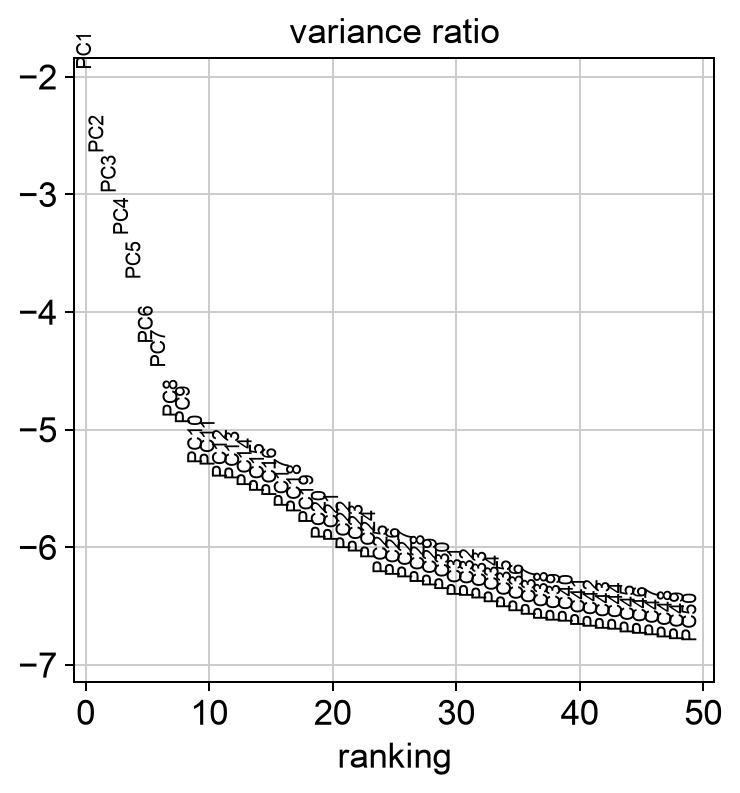

In [3]:
# Scale and run PCA on an HVG-only copy. Scaling the full matrix would densify
# ~20,000 genes x ~50,000 cells (several GB) for no benefit — only the HVGs
# enter the PCA anyway. This keeps peak memory to a few hundred MB, which
# matters on a laptop.
adata.X = adata.layers["lognorm"].copy()
_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(_hvg, max_value=10)
sc.tl.pca(_hvg, n_comps=cfg.N_PCS, svd_solver="arpack", random_state=cfg.RANDOM_SEED)

adata.obsm["X_pca"] = _hvg.obsm["X_pca"]
adata.uns["pca"] = _hvg.uns["pca"]
adata.varm["PCs"] = np.zeros((adata.n_vars, cfg.N_PCS), dtype=np.float32)
adata.varm["PCs"][adata.var["highly_variable"].values] = _hvg.varm["PCs"]
del _hvg

sc.pp.neighbors(adata, n_neighbors=cfg.N_NEIGHBORS, n_pcs=cfg.N_PCS,
                metric=cfg.KNN_METRIC, key_added="unintegrated",
                random_state=cfg.RANDOM_SEED)
sc.tl.umap(adata, neighbors_key="unintegrated", random_state=cfg.RANDOM_SEED)
adata.obsm["X_umap_unintegrated"] = adata.obsm["X_umap"].copy()

sc.pl.pca_variance_ratio(adata, n_pcs=cfg.N_PCS, log=True, show=True)

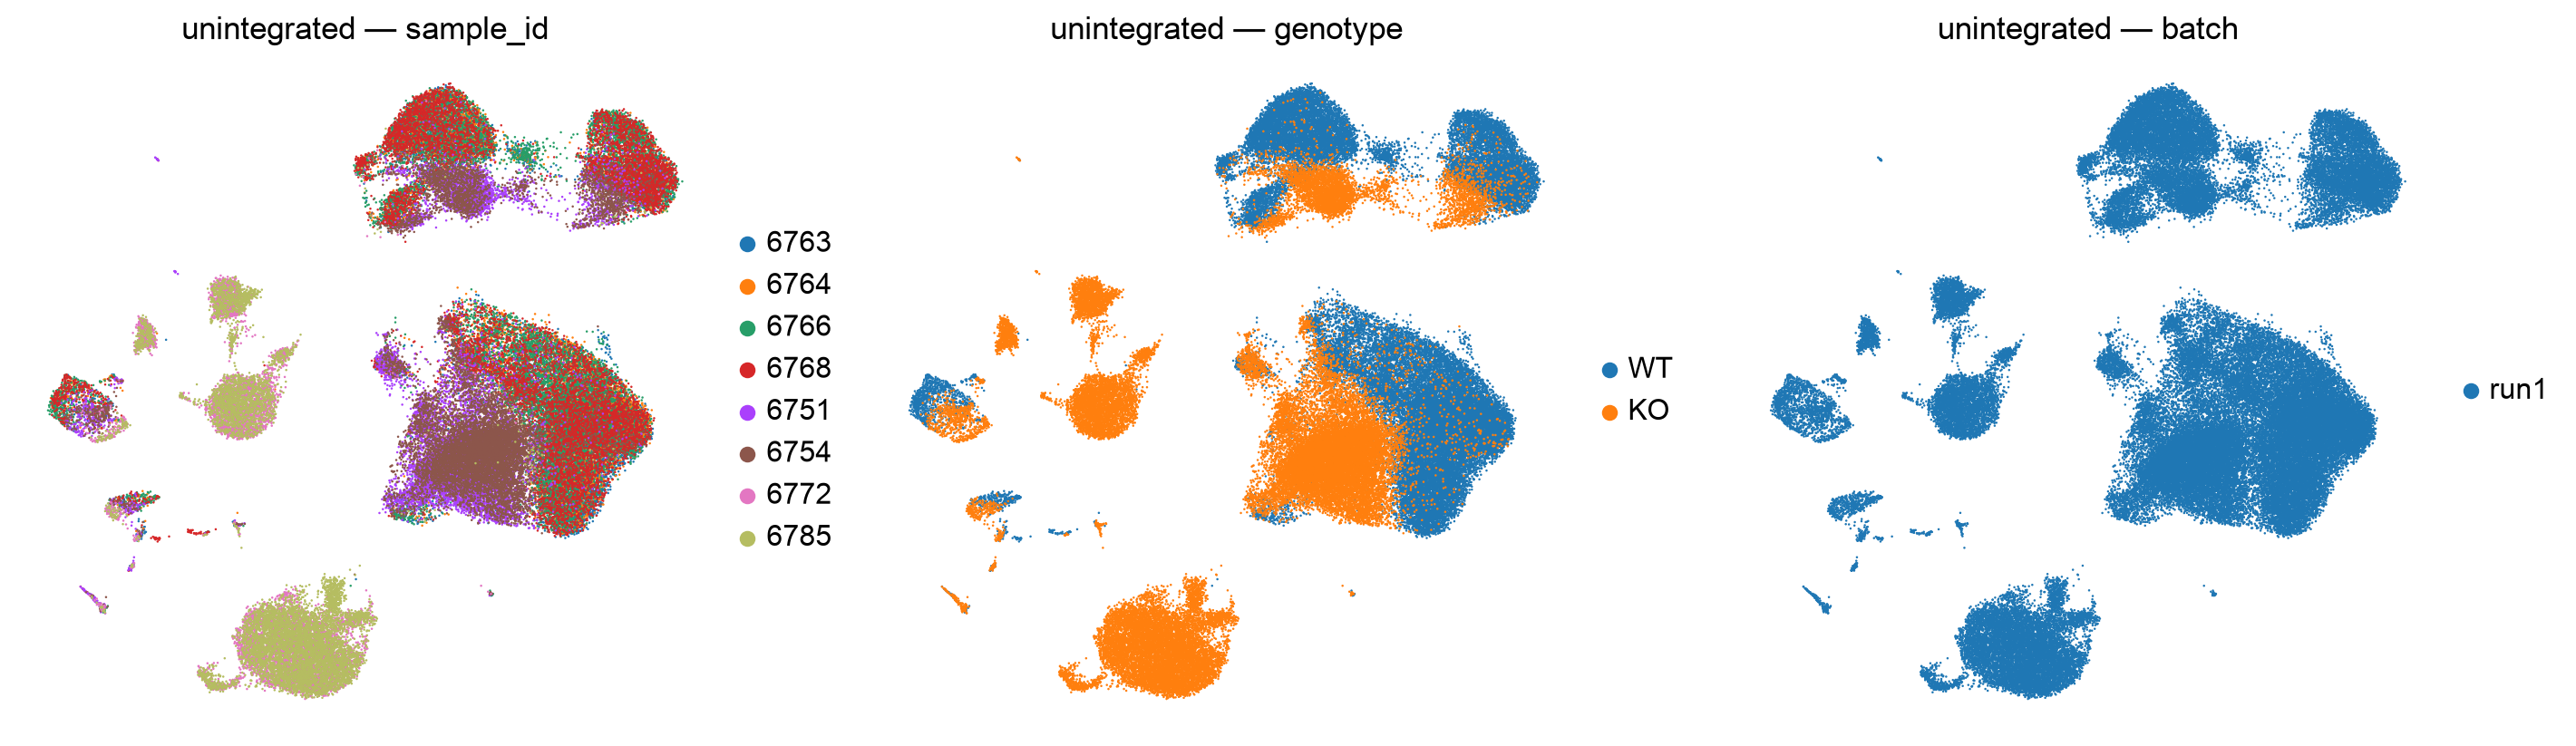

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, colour in zip(axes, ["sample_id", "genotype", "batch"]):
    sc.pl.embedding(adata, "X_umap_unintegrated", color=colour, ax=ax, show=False,
                    frameon=False, size=4, title=f"unintegrated — {colour}")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "02_umap_unintegrated.png", dpi=300, bbox_inches="tight")

### How to read that figure

- **Cells from all eight samples intermingled within each island** → batch
  effect is negligible. I can set `INTEGRATION_METHOD = "none"` in
  `config.py` and skip straight to notebook 03. This is a perfectly respectable
  outcome and is common for well-controlled single-lab islet experiments.
- **Islands split by `sample_id` but not by `genotype`** → technical batch
  effect. Integrate on `sample_id`.
- **Islands split cleanly by `genotype`** → ambiguous, and the interesting
  case. This is either a strong biological effect or a confound between
  genotype and processing day. Look at the `batch` panel: if KO and WT were run
  on different days, I cannot separate the two from this data alone, and I
  should say so explicitly in the paper.

The quantitative version of the same question:

In [5]:
print("unintegrated PCA:", batch_mixing_score(adata, "X_pca"))

unintegrated PCA: {'pct_same_batch_neighbours': 43.98, 'expected_if_perfectly_mixed': 12.5}


### 2.3 Harmony

Fast on CPU (seconds to a couple of minutes at this scale), operates on the PCA
embedding, and does not need a GPU. This is the default for your hardware.

`theta` controls correction strength. The scanpy default of 2 is fine; lower it
to 1 if you are worried about over-correction, which — given that genotype is
nested inside sample — you reasonably should be.

In [6]:
import time

t0 = time.time()
# scripts/integration.harmony_integrate, NOT sc.external.pp.harmony_integrate --
# the scanpy wrapper is broken against harmonypy 2.x (see that module's docstring)
harmony_integrate(
    adata,
    key=cfg.INTEGRATION_BATCH_KEY,
    basis="X_pca",
    adjusted_basis="X_pca_harmony",
    max_iter_harmony=20,
    theta=1.5,
    random_state=cfg.RANDOM_SEED,
)
print(f"harmony finished in {time.time() - t0:.0f}s")
print("harmony:", batch_mixing_score(adata, "X_pca_harmony"))

harmony finished in 25s
harmony: {'pct_same_batch_neighbours': 24.12, 'expected_if_perfectly_mixed': 12.5}


### 2.4 scVI — optional, and slower

scPoli's advantage comes from its prototype loss over *cell-type
labels*, which you do not yet have at this stage, and from sharing information
across hundreds of batches, which you do not have either. For eight samples
scVI is the sensible member of that family.

Expect **30–90 minutes on a laptop CPU** for ~50k cells. Skip it if Harmony's
mixing score already looks good — set `RUN_SCVI = False`. If I do run it,
`n_latent=30`, two layers and a negative-binomial likelihood reproduce the
HNOCA benchmark configuration.

In [9]:
RUN_SCVI = False        # flip to True if you want the comparison

if RUN_SCVI:
    import scvi

    scvi.settings.seed = cfg.RANDOM_SEED
    sub = adata[:, adata.var["highly_variable"]].copy()
    scvi.model.SCVI.setup_anndata(
        sub, layer="counts", batch_key=cfg.INTEGRATION_BATCH_KEY,
        continuous_covariate_keys=["pct_counts_mt"],
    )
    model = scvi.model.SCVI(sub, n_latent=30, n_layers=2, gene_likelihood="nb")
    t0 = time.time()
    model.train(max_epochs=200, early_stopping=True,
                early_stopping_patience=15, batch_size=512)
    print(f"scVI finished in {(time.time() - t0) / 60:.1f} min")
    adata.obsm["X_scvi"] = model.get_latent_representation()
    model.save(cfg.DATA_DIR / "scvi_model", overwrite=True)
    print("scVI:", batch_mixing_score(adata, "X_scvi"))

### 2.5 Choose an embedding and rebuild the graph

In [10]:
BASIS = {"harmony": "X_pca_harmony", "scvi": "X_scvi", "none": "X_pca"}[cfg.INTEGRATION_METHOD]
print(f"using {BASIS}")

sc.pp.neighbors(adata, use_rep=BASIS, n_neighbors=cfg.N_NEIGHBORS,
                metric=cfg.KNN_METRIC, random_state=cfg.RANDOM_SEED)
sc.tl.umap(adata, random_state=cfg.RANDOM_SEED)

# two resolutions: a fine one for the annotator, a coarse one for figures
sc.tl.leiden(adata, resolution=cfg.ANNOTATION_RESOLUTION, key_added="leiden_fine",
             flavor="igraph", n_iterations=2, directed=False, random_state=cfg.RANDOM_SEED)
sc.tl.leiden(adata, resolution=cfg.FINAL_RESOLUTION, key_added="leiden",
             flavor="igraph", n_iterations=2, directed=False, random_state=cfg.RANDOM_SEED)

print(f"leiden_fine: {adata.obs['leiden_fine'].nunique()} clusters "
      f"(annotation input — high is intentional)")
print(f"leiden:      {adata.obs['leiden'].nunique()} clusters (figures)")

using X_pca_harmony
leiden_fine: 46 clusters (annotation input — high is intentional)
leiden:      23 clusters (figures)


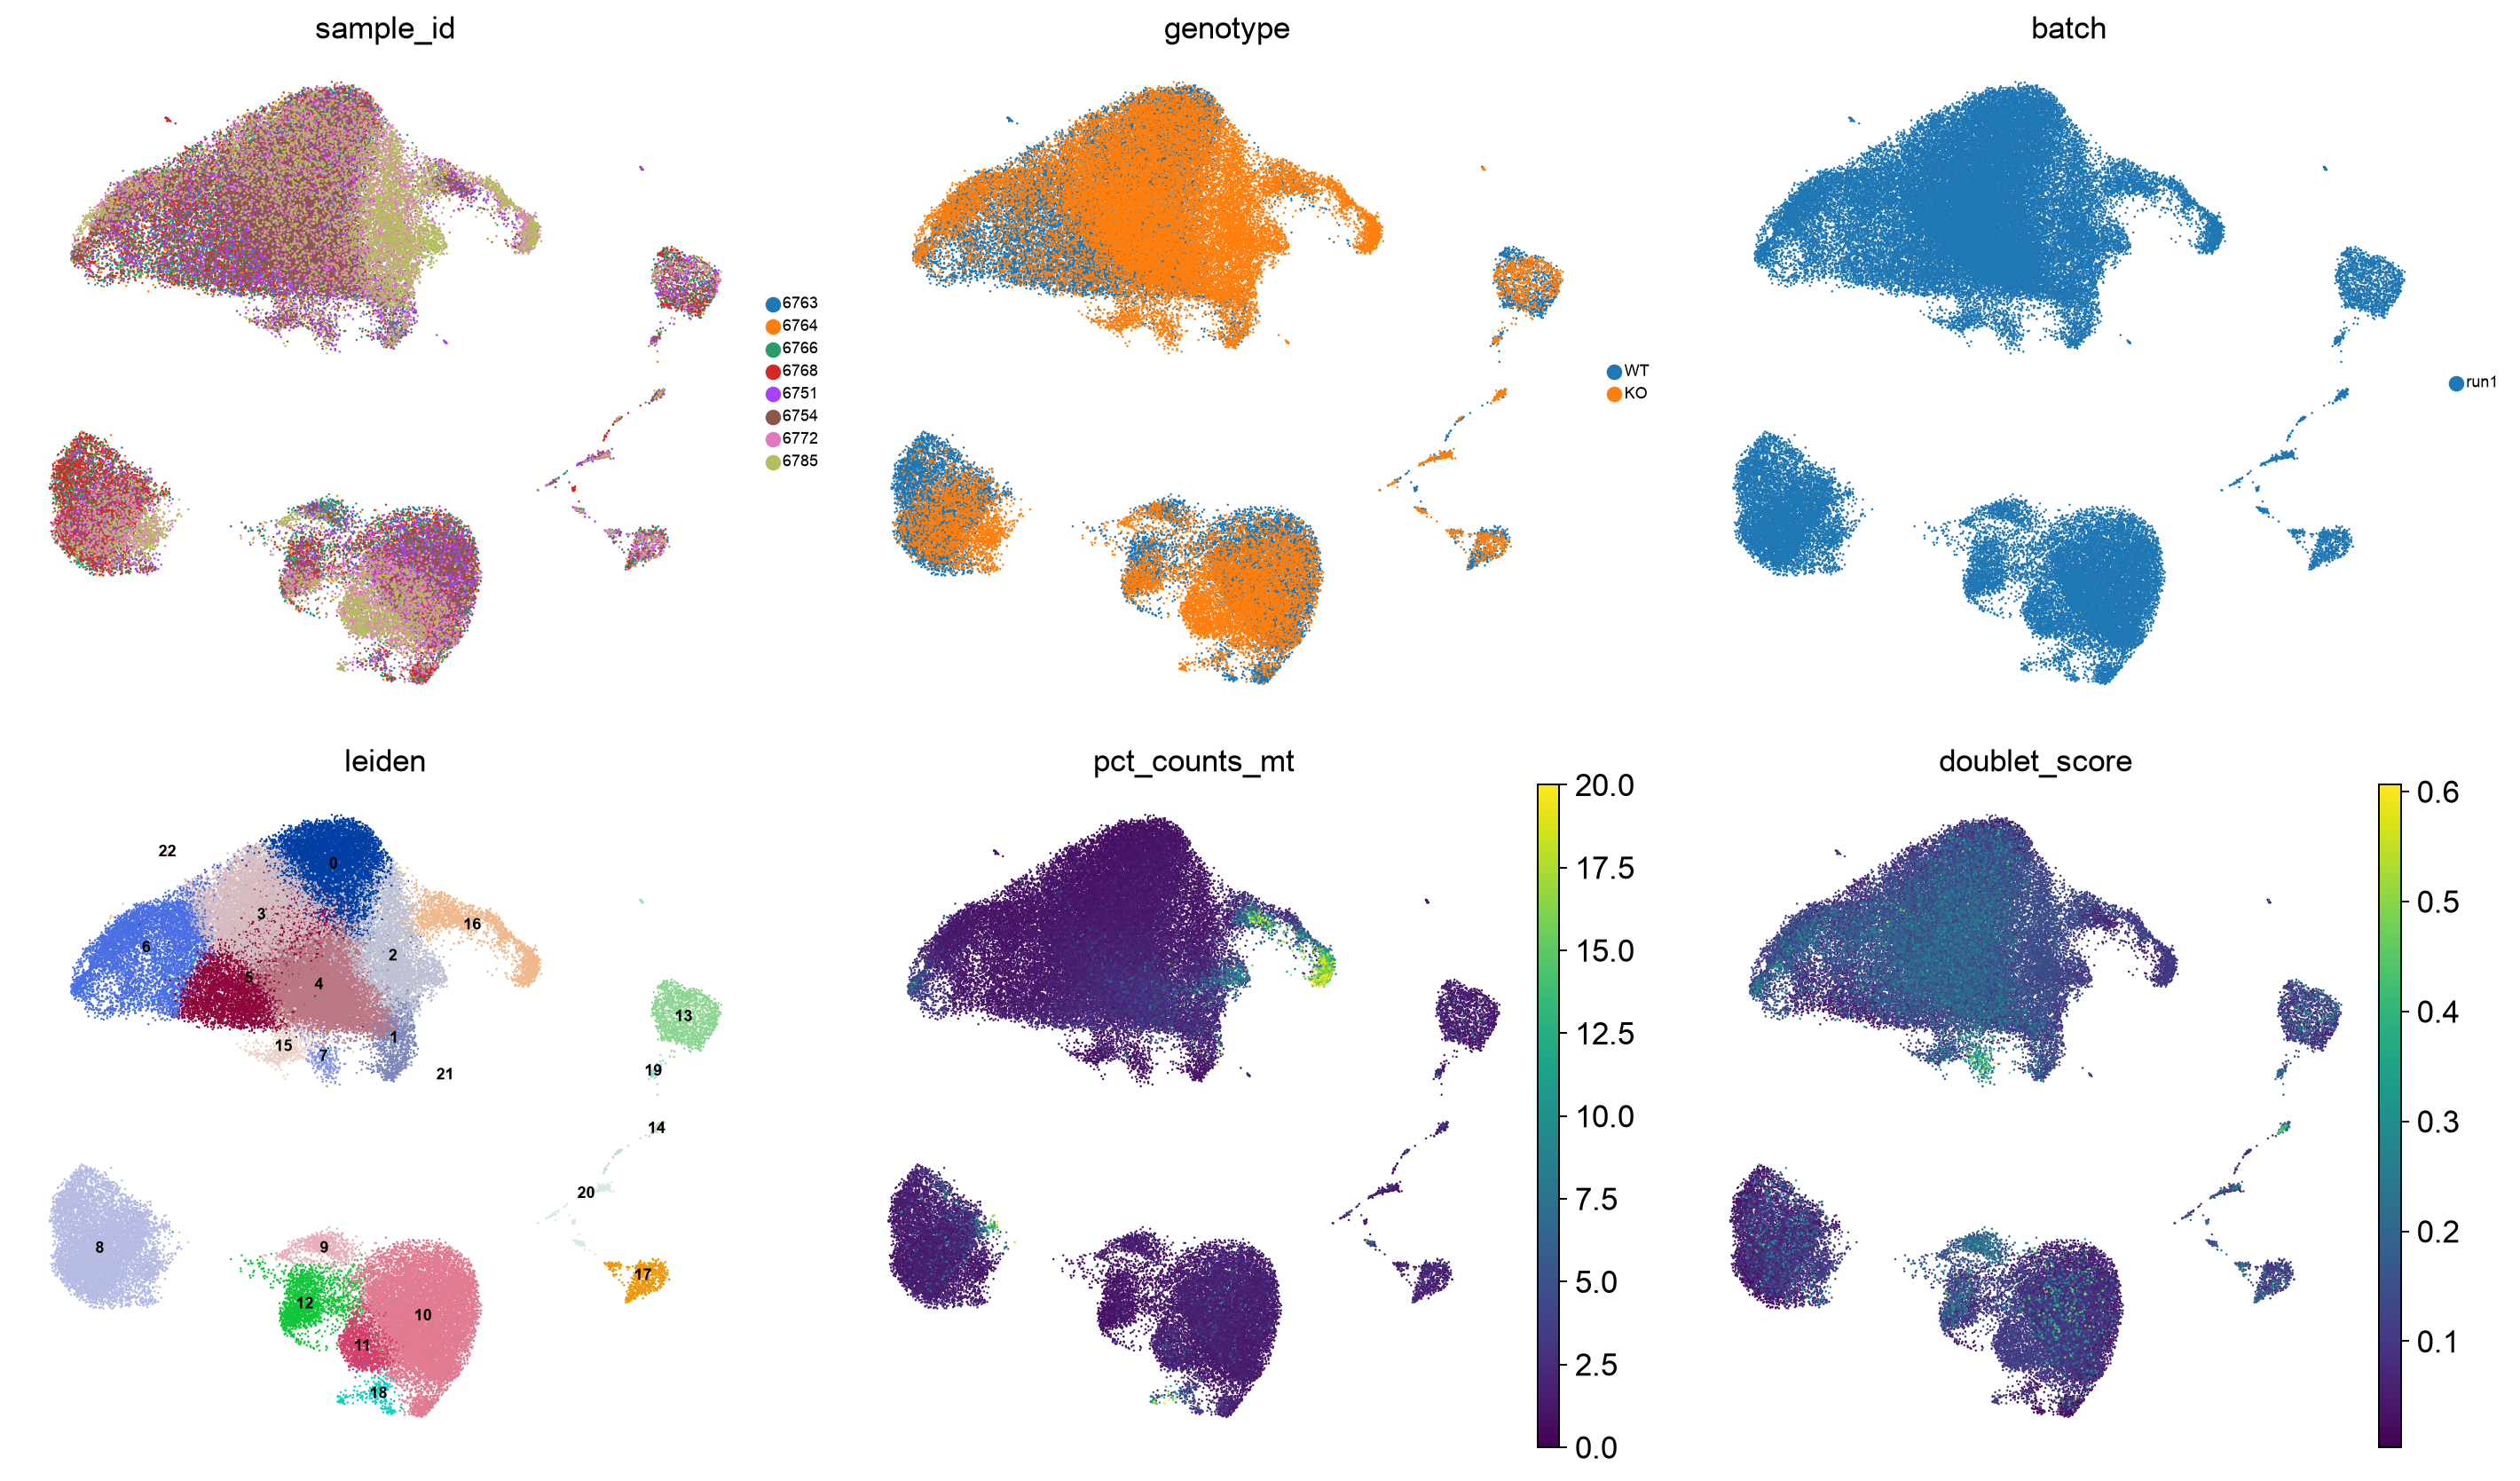

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
panels = ["sample_id", "genotype", "batch", "leiden", "pct_counts_mt", "doublet_score"]
for ax, colour in zip(axes.flat, panels):
    sc.pl.umap(adata, color=colour, ax=ax, show=False, frameon=False, size=4,
               legend_loc="on data" if colour == "leiden" else "right margin",
               legend_fontsize=7, title=colour)
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "02_umap_integrated.png", dpi=300, bbox_inches="tight")

### Marker overlay — a first look before formal annotation

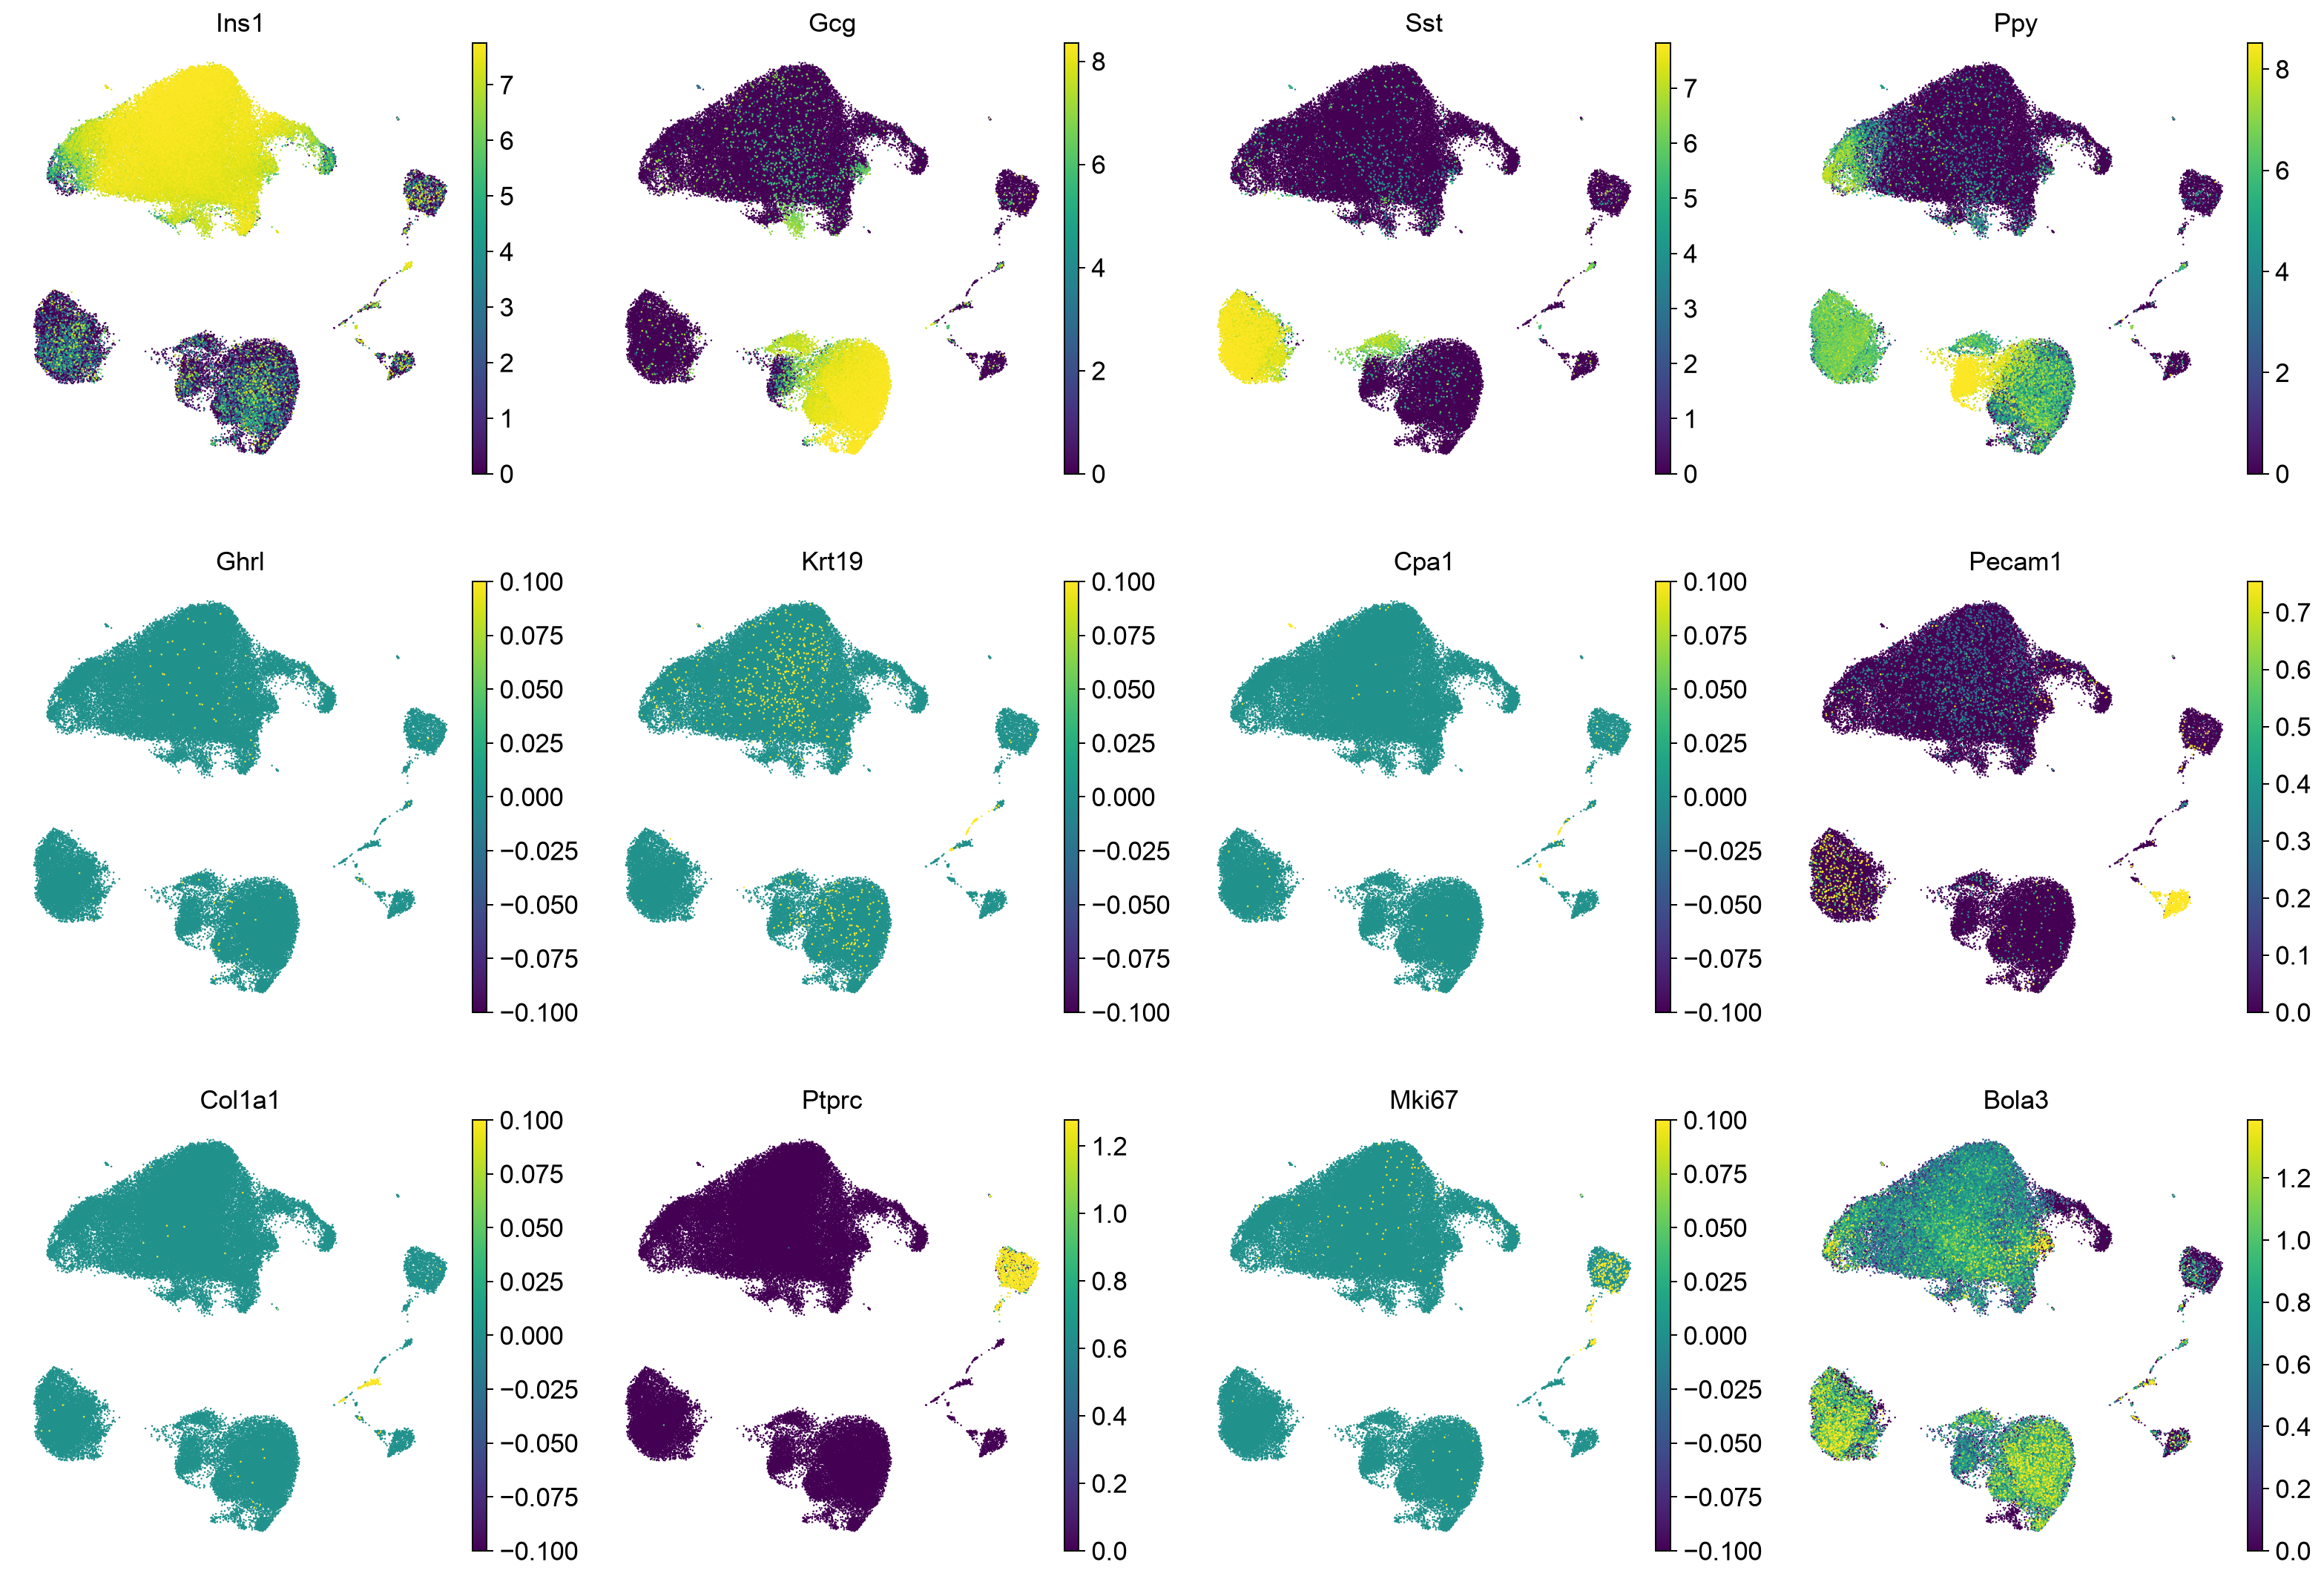

In [12]:
key_markers = [g for g in ["Ins1", "Gcg", "Sst", "Ppy", "Ghrl", "Krt19",
                           "Cpa1", "Pecam1", "Col1a1", "Ptprc", "Mki67", "Bola3"]
               if g in adata.var_names]
sc.pl.umap(adata, color=key_markers, ncols=4, size=4, frameon=False,
           cmap="viridis", vmax="p99", show=False)
plt.savefig(cfg.FIG_DIR / "02_umap_markers.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.6 Did integration distort the genotype signal?

The logic: pick a cluster, ask what fraction of its cells are KO. If
integration were purely removing technical noise, that fraction should be
roughly unchanged before and after. If integration is *homogenising your
genotypes*, every cluster will drift toward 50% KO.

spread of KO fraction across clusters: unintegrated 0.372 -> harmony 0.255


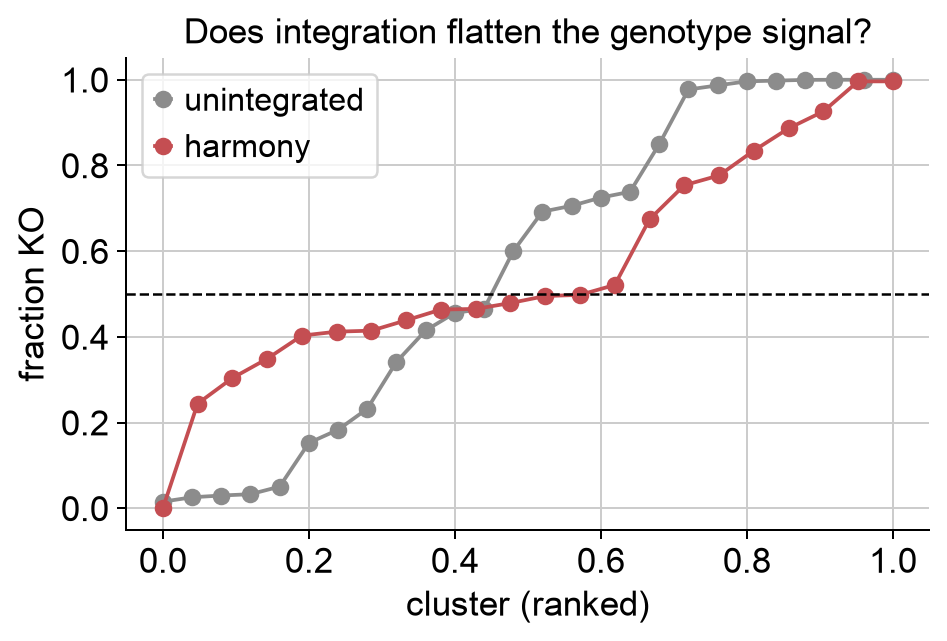

In [13]:
def genotype_fraction_by_cluster(adata, basis, resolution=1.0):
    tmp = adata.copy()
    sc.pp.neighbors(tmp, use_rep=basis, n_neighbors=cfg.N_NEIGHBORS,
                    metric=cfg.KNN_METRIC, random_state=cfg.RANDOM_SEED)
    sc.tl.leiden(tmp, resolution=resolution, key_added="cl", flavor="igraph",
                 n_iterations=2, directed=False, random_state=cfg.RANDOM_SEED)
    frac = (tmp.obs.groupby("cl", observed=True)["genotype"]
            .apply(lambda s: (s == "KO").mean()))
    return frac.sort_values().values


before = genotype_fraction_by_cluster(adata, "X_pca")
after = genotype_fraction_by_cluster(adata, BASIS)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(np.linspace(0, 1, len(before)), before, "o-", label="unintegrated", color="#8c8c8c")
ax.plot(np.linspace(0, 1, len(after)), after, "o-", label=cfg.INTEGRATION_METHOD, color="#C44E52")
ax.axhline(0.5, ls="--", c="k", lw=1)
ax.set_xlabel("cluster (ranked)"); ax.set_ylabel("fraction KO")
ax.set_title("Does integration flatten the genotype signal?")
ax.legend(); sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "02_genotype_flattening_check.png", dpi=300, bbox_inches="tight")

spread_before, spread_after = before.std(), after.std()
print(f"spread of KO fraction across clusters: "
      f"unintegrated {spread_before:.3f} -> {cfg.INTEGRATION_METHOD} {spread_after:.3f}")
if spread_after < 0.5 * spread_before:
    print("\nWARNING: integration has more than halved the between-cluster genotype "
          "spread. Consider theta=1.0, or INTEGRATION_METHOD='none'. Your DE in "
          "notebook 05 is unaffected either way — it uses raw counts — but your "
          "UMAP and your compositional analysis in notebook 04 both are.")

In [14]:
adata.write_h5ad(cfg.H5AD["integrated"])
print(f"wrote -> {cfg.H5AD['integrated']}")

wrote -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/processed/02_integrated.h5ad


---
### What to carry into notebook 03

- The embedding you chose, and why. If you chose `none`, say so — reviewers
  read "no batch correction applied" as a strength when it is justified.
- Whether any cluster is genotype-exclusive. A cluster that is 95% KO is either
  your headline result or a single-mouse artefact; the `sample_id` panel
  distinguishes them. If it comes from one mouse, it is not a phenotype.